In [1]:
#Get the building data for the study area using LINZ service.

import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.gpkg"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

#convert dem bounds to bbox coordinates to ESPG:4167 (NZGD2000)
# from pyproj import Transformer
# transformer = Transformer.from_crs(dem_crs, "EPSG:4167", always_xy=True)
# left, bottom = transformer.transform(dem_bounds.left, dem_bounds.bottom)
# right, top = transformer.transform(dem_bounds.right, dem_bounds.top)


bbox = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top}"

# Assumes dem_bounds is already in NZTM2000 (EPSG:2193)
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

wfs_url = (
    f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
    f"service=WFS&version=2.0.0&request=GetFeature"
    f"&typeNames=layer-101290"
    f"&bbox={bbox_str}"
    f"&outputFormat=application/json"
)

buildings = gpd.read_file(wfs_url)
print(f"Fetched {len(buildings)} buildings")

# Save the building data to a GeoJSON file
buildings.to_file(BUILDING_FILE_PATH, driver="gpkg")
print(f"Building data saved to {BUILDING_FILE_PATH}")

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Fetched 6143 buildings
Building data saved to /data/westport/data/exposure/buildings.gpkg


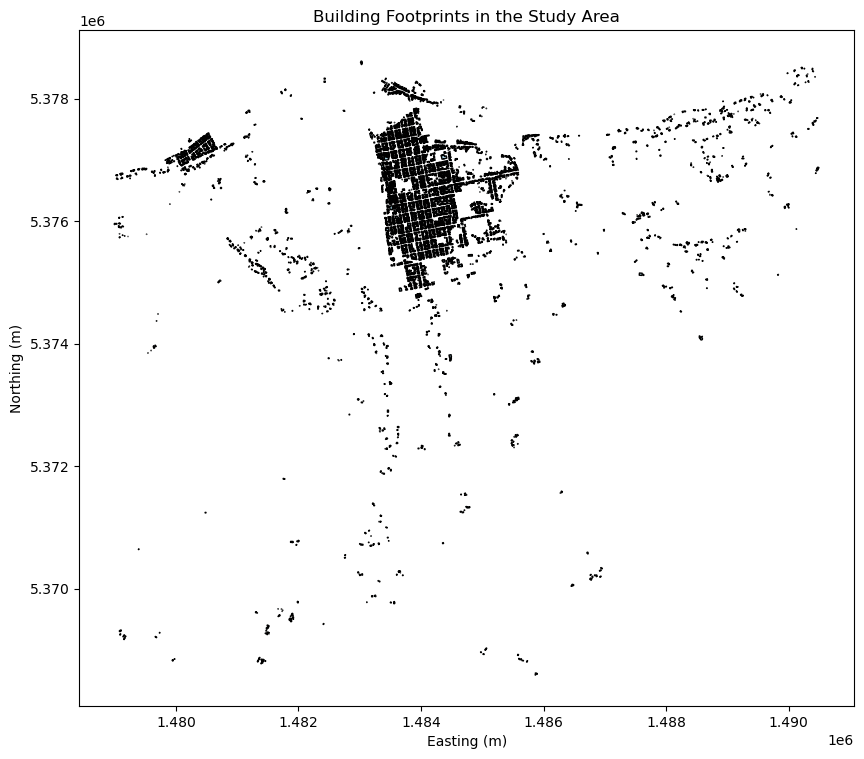

Min building area: 10.0 m²
Max building area: 7560.8 m²
Mean building area: 143.9 m²
Median building area: 114.7 m²


In [2]:
#plot the buildings
import matplotlib.pyplot as plt 
fig, ax = plt.subplots(figsize=(10, 10))
buildings.plot(ax=ax, color='lightblue', edgecolor='black')
ax.set_title("Building Footprints in the Study Area")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.show()


# Make sure you're in a projected CRS for accurate area in m²
buildings_projected = buildings.to_crs(epsg=2193)

print(f"Min building area: {buildings_projected.geometry.area.min():.1f} m²")
print(f"Max building area: {buildings_projected.geometry.area.max():.1f} m²")
print(f"Mean building area: {buildings_projected.geometry.area.mean():.1f} m²")
print(f"Median building area: {buildings_projected.geometry.area.median():.1f} m²")

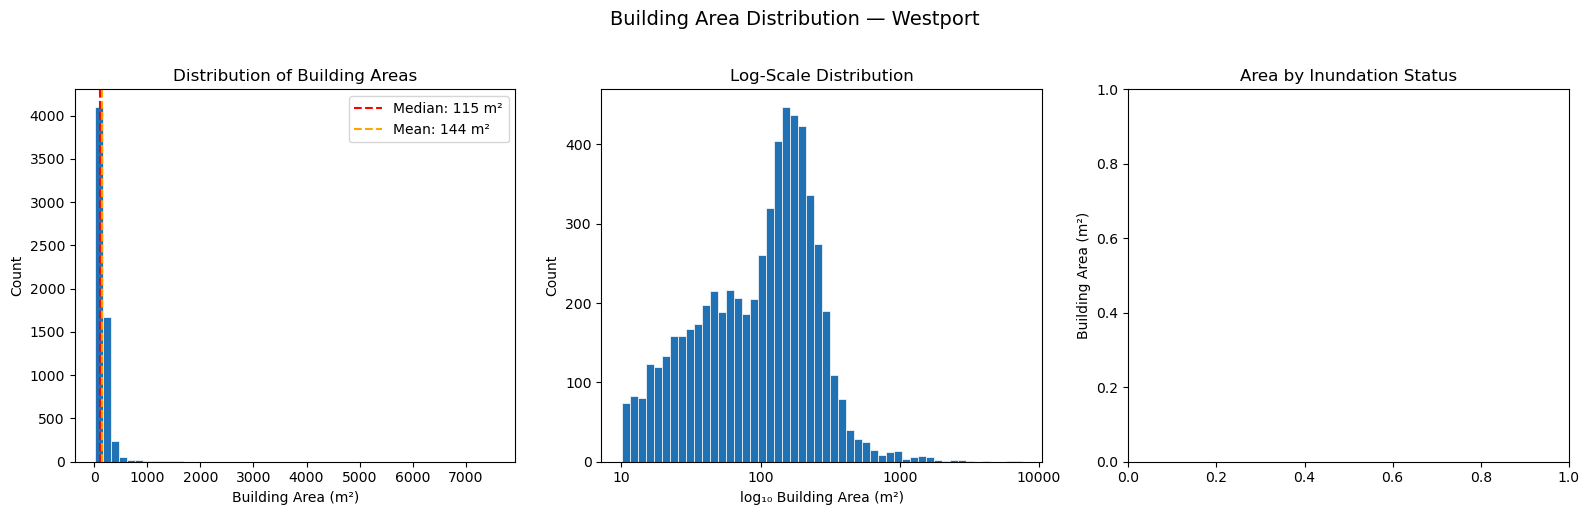

In [5]:
import matplotlib.pyplot as plt
import numpy as np

buildings_projected = buildings.to_crs(epsg=2193)
area = buildings_projected.geometry.area

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── 1. HISTOGRAM ──────────────────────────────────────────────────────────────
axes[0].hist(area, bins=50, color="#2171b5", edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Building Area (m²)")
axes[0].set_ylabel("Count")
axes[0].set_title("Distribution of Building Areas")
axes[0].axvline(area.median(), color="red",    linestyle="--", label=f"Median: {area.median():.0f} m²")
axes[0].axvline(area.mean(),   color="orange", linestyle="--", label=f"Mean: {area.mean():.0f} m²")
axes[0].legend()

# ── 2. LOG-SCALE HISTOGRAM (handles skew better) ──────────────────────────────
axes[1].hist(np.log10(area), bins=50, color="#2171b5", edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("log₁₀ Building Area (m²)")
axes[1].set_ylabel("Count")
axes[1].set_title("Log-Scale Distribution")
axes[1].set_xticks([1, 2, 3, 4])
axes[1].set_xticklabels(["10", "100", "1000", "10000"])

# ── 3. BOXPLOT BY INUNDATION STATUS ───────────────────────────────────────────
buildings_projected["area"]      = area

axes[2].set_ylabel("Building Area (m²)")
axes[2].set_title("Area by Inundation Status")

plt.suptitle("Building Area Distribution — Westport", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [9]:
!pip install rasterstats

2208.73s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rasterstats]


In [13]:
# Overlay flood extent on the building footprints
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
from rasterstats import zonal_stats

# ── CONFIGURATION ─────────────────────────────────────────────────────────────

SIMULATION_DATA_DIR = f"/data/westport/data"
FLOOD_MAP_FILE_PATH = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/July_2021_surveyed_flood_depth.tif"
DEPTH_RASTER    = FLOOD_MAP_FILE_PATH
BUILDING_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"

DEPTH_THRESHOLD = 0.1   # m  — minimum depth to count as inundated

pythongrey_red = LinearSegmentedColormap.from_list(
    "grey_red", ["#000000", "#fc8d59", "#d7191c"]  # grey → orange → deep red
)

# ── LOAD BUILDINGS ────────────────────────────────────────────────────────────

buildings = gpd.read_file(BUILDING_FILE_PATH)
buildings = buildings[buildings.geometry.area >= 50].reset_index(drop=True)
print(f"Loaded {len(buildings)} buildings")

# ── REPROJECT BUILDINGS TO RASTER CRS ─────────────────────────────────────────

with rasterio.open(DEPTH_RASTER) as src:
    raster_crs = src.crs
    nodata     = src.nodata

buildings = buildings.to_crs(raster_crs)

# ── ZONAL STATS ───────────────────────────────────────────────────────────────

depth_stats = zonal_stats(buildings, DEPTH_RASTER,
                          stats=["max", "mean"], nodata=nodata, all_touched=False)
# vel_stats   = zonal_stats(buildings, VELOCITY_RASTER,
#                           stats=["max", "mean"], nodata=nodata, all_touched=False)

buildings["depth_max"]  = [s["max"]  or 0.0 for s in depth_stats]
buildings["depth_mean"] = [s["mean"] or 0.0 for s in depth_stats]
# buildings["vel_max"]    = [s["max"]  or 0.0 for s in vel_stats]
# buildings["dv_product"] = buildings["depth_max"] * buildings["vel_max"]
buildings["inundated"]  = buildings["depth_max"] >= DEPTH_THRESHOLD

print(f"Inundated buildings: {buildings['inundated'].sum()} "
      f"({buildings['inundated'].mean()*100:.1f}%)")



Loaded 4439 buildings
Inundated buildings: 1855 (41.8%)


In [ ]:
import folium
import json
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib import cm

import os
os.system(f"jupyter trust {os.path.abspath('your_notebook_name.ipynb')}")

# ── COLORMAP: grey → red ──────────────────────────────────────────────────────

grey_red = LinearSegmentedColormap.from_list("grey_red", ["#d3d3d3", "#fc8d59", "#d7191c"])

def depth_to_hex(depth):
    if depth < 0.1:
        return "#2ecc71"   # green
    elif depth < 0.3:
        return "#f1c40f"   # yellow
    else:
        return "#e74c3c"   # red

# ── REPROJECT TO WGS84 (folium requires lat/lon) ──────────────────────────────

buildings_wgs = buildings.to_crs(epsg=4326)

# ── CENTRE MAP ON INUNDATED BUILDINGS ─────────────────────────────────────────

inundated_wgs = buildings_wgs[buildings_wgs["inundated"]]
centre = inundated_wgs.dissolve().centroid.iloc[0]

m = folium.Map(
    location=[centre.y, centre.x],
    zoom_start=15,
    tiles="Esri.WorldImagery",  # satellite basemap
    attr="Esri"
)

# ── ADD BUILDINGS ─────────────────────────────────────────────────────────────

for _, row in buildings_wgs.iterrows():
    depth = row["depth_max"]
    colour = depth_to_hex(depth) if row["inundated"] else "#aaaaaa"

    folium.GeoJson(
        row["geometry"].__geo_interface__,
        style_function=lambda x, c=colour: {
            "fillColor": c,
            "color": "black",
            "weight": 0.5,
            "fillOpacity": 0.8
        },
        tooltip=folium.Tooltip(
            f"Depth: {depth:.2f} m<br>"
            f"Inundated: {row['inundated']}"
        )
    ).add_to(m)
    
# -- ADD INUNDATION MAP OVERLAY (OPTIONAL) ────────────────────────────────────────────────────────



# ── ADD LEGEND ────────────────────────────────────────────────────────────────

legend_html = """
<div style="position: fixed; bottom: 40px; left: 40px; z-index: 1000;
     background-color: white; padding: 12px; border-radius: 6px;
     border: 1px solid grey; font-size: 13px;">
  <b>Max Flood Depth (m)</b><br>
  <i style="background:#2ecc71;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &lt; 0.1 m (shallow)<br>
  <i style="background:#f1c40f;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> 0.1 – 0.3 m (moderate)<br>
  <i style="background:#e74c3c;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &gt; 0.3 m (deep)<br>
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))

# ── DISPLAY ───────────────────────────────────────────────────────────────────

m.save("flood_map.html")

from IPython.display import IFrame
# IFrame("flood_map.html", width="100%", height=600)

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Study Area Bounds (transformed): [19095898.39747464 -5136149.29453732 19111682.36085452 -5120103.06572846]


AttributeError: 'dict' object has no attribute 'build_url'

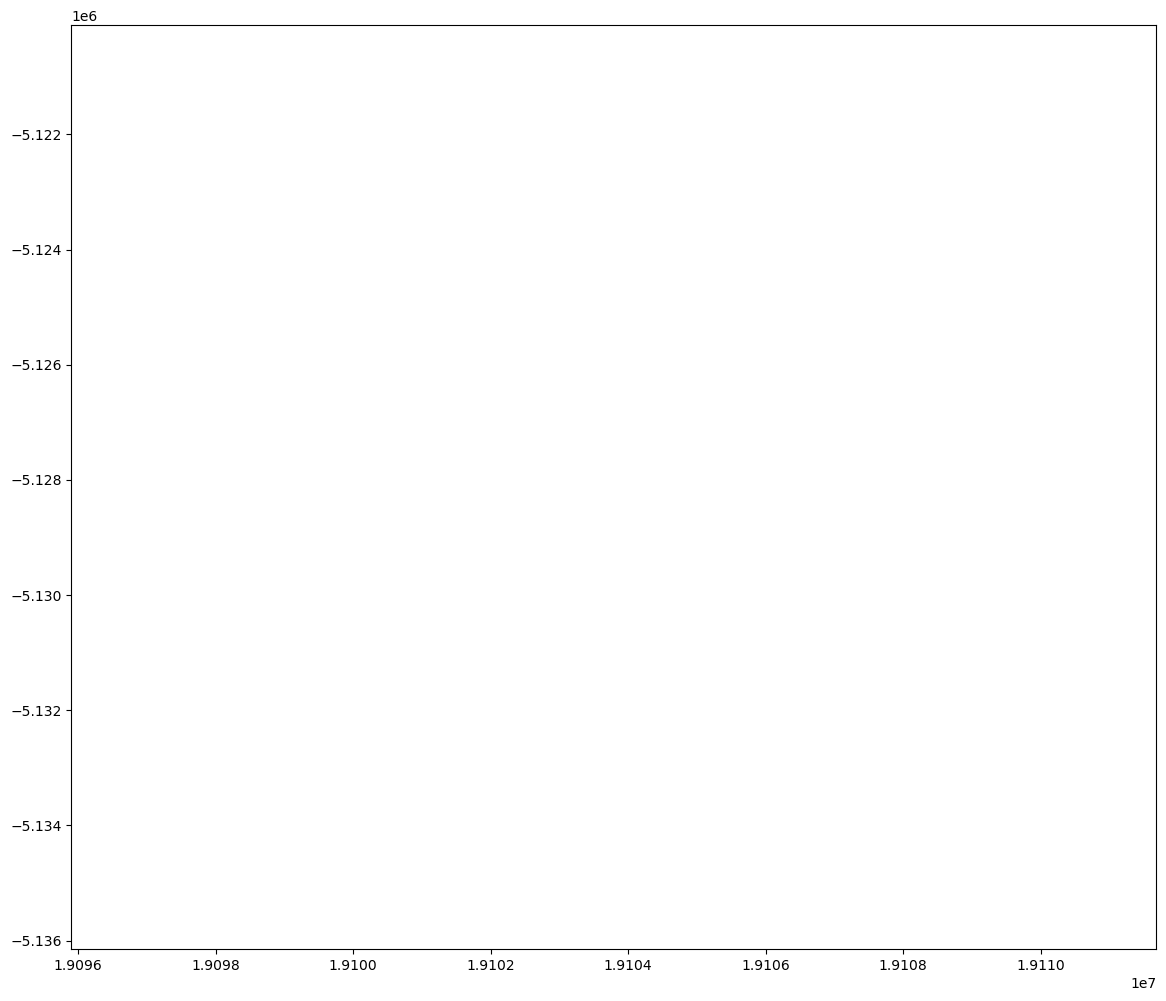

In [14]:
import geopandas as gpd
from shapely.geometry import box
import matplotlib.pyplot as plt
import contextily as ctx
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/Topo.tif"

# Open the DEM file to get coordinate bounds
with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    # Get bounds of the DEM data directly from dataset
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs
    
print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

# Create a bounding box from the DEM bounds (left, bottom, right, top)
study_area_box = box(dem_bounds.left, dem_bounds.bottom, dem_bounds.right, dem_bounds.top)
study_area_gdf = gpd.GeoDataFrame([1], geometry=[study_area_box], crs=dem_crs)

# Only reproject if CRS is not Web Mercator
if dem_crs and dem_crs.to_string() != "EPSG:3857":
    study_area_gdf_web = study_area_gdf.to_crs(epsg=3857)
else:
    study_area_gdf_web = study_area_gdf.copy()

print(f"Study Area Bounds (transformed): {study_area_gdf_web.bounds.values[0]}")

# Create figure with satellite basemap
fig, ax = plt.subplots(figsize=(14, 12))

# Set axis limits to the study area before adding basemap
bounds_row = study_area_gdf_web.bounds.iloc[0]
ax.set_xlim(bounds_row['minx'], bounds_row['maxx'])
ax.set_ylim(bounds_row['miny'], bounds_row['maxy'])

# Get the base map for the study area using LINZ service
koordinates = {
    "url": "https://data.linz.govt.nz/services/query/v1/vector.json?key=a06a74b6c02f4d4a81f999bd09034897&layer=101292&x=[x]&y=[y]&max_results=3&radius=10000&geometry=true&with_field_names=true",
    "attribution": "© Koordinates / LINZ"
}

ctx.add_basemap(ax, source=koordinates, crs=study_area_gdf_web.crs.to_string(), zoom=12)
# Plot the study area boundary on top of the basemap
study_area_gdf_web.boundary.plot(ax=ax, edgecolor='red', linewidth=2)
ax.set_title("Study Area with LINZ Basemap", fontsize=16)
ax.set_axis_off()
plt.show()

In [2]:
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap, Normalize
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium import raster_layers
from IPython.display import IFrame
import base64
from io import BytesIO

# ── CONFIGURATION ─────────────────────────────────────────────────────────────

SIMULATION_DATA_DIR  = "/data/westport/data"
DEPTH_RASTER         = f"{SIMULATION_DATA_DIR}/flood-mapping-with-ml-main-DATA/DATA/July_2021_surveyed_flood_depth.tif"
BUILDING_FILE_PATH   = f"{SIMULATION_DATA_DIR}/exposure/buildings.geojson"
DEPTH_THRESHOLD      = 0.1

# ── LOAD & PROCESS BUILDINGS (your existing code) ─────────────────────────────

buildings = gpd.read_file(BUILDING_FILE_PATH)
buildings = buildings[buildings.geometry.area >= 50].reset_index(drop=True)

with rasterio.open(DEPTH_RASTER) as src:
    raster_crs = src.crs
    nodata     = src.nodata
    

buildings = buildings.to_crs(raster_crs)

from rasterstats import zonal_stats
depth_stats = zonal_stats(buildings, DEPTH_RASTER,
                          stats=["max", "mean"], nodata=nodata, all_touched=False)
buildings["depth_max"]  = [s["max"]  or 0.0 for s in depth_stats]
buildings["depth_mean"] = [s["mean"] or 0.0 for s in depth_stats]
buildings["inundated"]  = buildings["depth_max"] >= DEPTH_THRESHOLD

print(f"Inundated buildings: {buildings['inundated'].sum()} "
      f"({buildings['inundated'].mean()*100:.1f}%)")



# ── REPROJECT RASTER TO WGS84 FOR FOLIUM ──────────────────────────────────────

def raster_to_wgs84_array(raster_path, nodata_val):
    with rasterio.open(raster_path) as src:
        transform, width, height = calculate_default_transform(
            src.crs, "EPSG:4326", src.width, src.height, *src.bounds
        )
        data = np.zeros((height, width), dtype=np.float32)
        reproject(
            source=rasterio.band(src, 1),
            destination=data,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            resampling=Resampling.bilinear
        )

        # Get WGS84 bounds [south, west, north, east]
        from rasterio.transform import array_bounds
        west, south, east, north = rasterio.transform.array_bounds(height, width, transform)

    # Fix 1: Replace nodata and nan with 0
    if nodata_val is not None:
        data[data == nodata_val] = 0.0
    data = np.nan_to_num(data, nan=0.0)

    # Mask dry areas
    mask = data <= DEPTH_THRESHOLD

    # Fix 2: Clip data to valid range before normalising to avoid overflow
    valid_data = data[~mask]
    if len(valid_data) == 0:
        print("WARNING: No flooded pixels found in raster")
        return None, None

    vmax = float(np.percentile(valid_data, 95))
    data_clipped = np.clip(data, DEPTH_THRESHOLD, vmax)

    blue = LinearSegmentedColormap.from_list(
    "blue_flood", ["#deebf7", "#9ecae1", "#2171b5", "#08306b"]  # very light → deep navy
    )       
    norm = Normalize(vmin=DEPTH_THRESHOLD, vmax=vmax)
    rgba = blue(norm(data_clipped), bytes=True)
    rgba[mask, 3] = 0   # transparent where dry

    # Fix 3: Correct bounds order for folium [[south, west], [north, east]]
    bounds = [[south, west], [north, east]]
    print(f"Raster WGS84 bounds: S={south:.4f}, W={west:.4f}, N={north:.4f}, E={east:.4f}")

    return rgba, bounds

rgba_array, raster_bounds = raster_to_wgs84_array(DEPTH_RASTER, nodata)


# Convert RGBA array to base64 PNG for folium ImageOverlay
buf = BytesIO()
plt.imsave(buf, rgba_array, format="png")
buf.seek(0)
img_b64 = base64.b64encode(buf.read()).decode("utf-8")
img_url = f"data:image/png;base64,{img_b64}"

# ── BUILD FOLIUM MAP ───────────────────────────────────────────────────────────

buildings_wgs = buildings.to_crs(epsg=4326)
inundated_wgs = buildings_wgs[buildings_wgs["inundated"]]

centre = (inundated_wgs.to_crs(epsg=2193)
                       .dissolve()
                       .centroid
                       .to_crs(epsg=4326)
                       .iloc[0])

keep_cols = ["geometry", "depth_max", "depth_mean", "inundated"]
buildings_wgs = buildings.to_crs(epsg=4326)[keep_cols]


m = folium.Map(
    location=[centre.y, centre.x],
    zoom_start=15,
    tiles="Esri.WorldImagery",
    attr="Esri"
)

# ── LAYER 1: FLOOD RASTER ─────────────────────────────────────────────────────

folium.raster_layers.ImageOverlay(
    image=img_url,
    bounds=[[-41.8334, 171.5518], [-41.7296, 171.6724]],  # hardcode from your print output
    opacity=0.8,
    name="Flood Depth Raster",
    interactive=False,
    cross_origin=False, 
    z_index=1
).add_to(m)


# ── LAYER 3: JUST BUILDINGS  ────────────────────────────────────────────────────────

folium.GeoJson(
    buildings_wgs.__geo_interface__,
    name="Buildings",
    style_function=lambda x: {
        "fillColor": "#cccccc",
        "color":     "black",
        "weight":    0.8,
        "fillOpacity": 0.2
    },
    # tooltip=folium.GeoJsonTooltip(
    #     fields=["area"],
    #     aliases=["Area (m²)"]
    # )
).add_to(m)


# ── LAYER 3: BUILDINGS EXPOSURE ────────────────────────────────────────────────────────

def depth_to_hex(depth):
    if depth < 0.1:
        return "#2ecc71"
    elif depth < 0.3:
        return "#f1c40f"
    else:
        return "#e74c3c"

folium.GeoJson(
    buildings_wgs.__geo_interface__,
    name="Buildings Exposure",
    style_function=lambda x: {
        "fillColor": depth_to_hex(x["properties"]["depth_max"]),
        "color":     "black",
        "weight":    0.8,
        "fillOpacity": 0.9 if x["properties"]["inundated"] else 0.2
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["depth_max", "depth_mean", "inundated"],
        aliases=["Max Depth (m)", "Mean Depth (m)", "Inundated"]
    )
).add_to(m)

# ___ LAYER 4: PLACRD DATA ────────────────────────────────────────────────────────
#Placard data
import geopandas as gpd
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"

#Visualise the placard data
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

def placard_color(color_val):
    color_map = {
        "Red":   "#e74c3c",
        "Green": "#2ecc71",
        "1":     "#f1c40f",   # MBIE records with no colour — assign yellow
    }
    return color_map.get(str(color_val), "#aaaaaa")  # grey as fallback

placard_layer = folium.FeatureGroup(name="Placards")

folium.GeoJson(
    placards.__geo_interface__,
    style_function=lambda x: {
        "fillColor":   placard_color(x["properties"]["color"]),
        "color":       "black",
        "weight":      1,
        "fillOpacity": 0.8
    },
    tooltip=folium.GeoJsonTooltip(
        fields=  ["damage",    "color",  "source", "DamageNb"],
        aliases= ["Damage",    "Color",  "Source", "Damage Level"]
    )
).add_to(placard_layer)


placard_layer.add_to(m)


# ── LAYER CONTROL + LEGEND ────────────────────────────────────────────────────

folium.LayerControl().add_to(m)

legend_html = """
<div style="position: fixed; bottom: 40px; left: 40px; z-index: 1000;
     background-color: white; padding: 12px; border-radius: 6px;
     border: 1px solid grey; font-size: 13px;">
  <b>Max Flood Depth (m)</b><br>
  <i style="background:#2ecc71;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &lt; 0.1 m<br>
  <i style="background:#f1c40f;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> 0.1 – 0.3 m<br>
  <i style="background:#e74c3c;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> &gt; 0.3 m<br>
  <hr style="margin:6px 0">
  <b>Flood Raster</b><br>
  <b>Flood Depth Raster</b><br>
  <i style="background:#deebf7;width:14px;height:14px;display:inline-block;margin-right:6px;border:1px solid #ccc;"></i> Shallow (0.1 m)<br>
  <i style="background:#9ecae1;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> Moderate (0.5 m)<br>
  <i style="background:#2171b5;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> Deep (1.0 m)<br>
  <i style="background:#08306b;width:14px;height:14px;display:inline-block;margin-right:6px;"></i> Very deep (&gt; 2.0 m)<br>
  <hr style="margin:6px 0">
  <b>Placards</b><br>
  <i style="background:#9b59b6;width:14px;height:14px;display:inline-block;
     margin-right:6px;border-radius:50%;"></i> Placard location<br>
  
</div>
"""
m.get_root().html.add_child(folium.Element(legend_html))


# opacity_slider = """
# <div style="position: fixed; top: 40px; right: 40px; z-index: 1000;
#      background-color: white; padding: 10px; border-radius: 6px;
#      border: 1px solid grey; font-size: 13px;">
#   <b>Flood Raster Opacity</b><br>
#   <input type="range" min="0" max="1" step="0.1" value="0.6"
#      oninput="document.querySelectorAll('.leaflet-image-layer')[0].style.opacity = this.value">
# </div>
# """
# m.get_root().html.add_child(folium.Element(opacity_slider))

# ── SAVE & DISPLAY ────────────────────────────────────────────────────────────

m.save("flood_exposure_map.html")
# IFrame("flood_exposure_map.html", width="100%", height=700)

Inundated buildings: 1855 (41.8%)
Raster WGS84 bounds: S=-41.8334, W=171.5518, N=-41.7296, E=171.6724


In [ ]:
# Make sure you're in a projected CRS for accurate area in m²
buildings_projected = buildings.to_crs(epsg=2193)

print(f"Min building area: {buildings_projected.geometry.area.min():.1f} m²")
print(f"Max building area: {buildings_projected.geometry.area.max():.1f} m²")
print(f"Mean building area: {buildings_projected.geometry.area.mean():.1f} m²")
print(f"Median building area: {buildings_projected.geometry.area.median():.1f} m²")

In [ ]:

placards = placards.to_crs(epsg=4326)

               damage  color source  building_id  DamageNb  \
0      Moderatedamage    Red   USAR    2513595.0       2.0   
1               light      1   MBIE    2513596.0       1.0   
2               light      1   MBIE    2513597.0       1.0   
3  NodamageUnaffected  Green   USAR    2513599.0       0.0   
4  NodamageUnaffected  Green   USAR    2513600.0       0.0   

                                            geometry  
0  MULTIPOLYGON (((171.60776 -41.74892, 171.60778...  
1  MULTIPOLYGON (((171.6079 -41.74854, 171.60805 ...  
2  MULTIPOLYGON (((171.6077 -41.74868, 171.60773 ...  
3  MULTIPOLYGON (((171.60784 -41.74822, 171.60783...  
4  MULTIPOLYGON (((171.60809 -41.74822, 171.60809...  


In [2]:

import geopandas as gpd
PROJECT_ROOT = "/home/91/23016891/projects/carlisle"
ANALYSIS_DIR = f"{PROJECT_ROOT}/out/exposure_analysis"
PLACRD_FILE_PATH = "/data/westport/data/Impact-based_data/obs_placard.gpkg"
placards = gpd.read_file(PLACRD_FILE_PATH)
placards = placards.to_crs(epsg=4326)

#make sure that the directory exists
import os
os.makedirs(ANALYSIS_DIR, exist_ok=True)

#get some stats about the data
# Total houses surveyed
total_entries = len(placards)
#number of unique houses (by building ID)
total_houses = placards["building_id"].nunique()
print(f"Total entries: {total_entries}")
print(f"Total houses surveyed: {total_houses}")

damage_numbers_unique = placards["DamageNb"].unique()
print(f"Unique damage levels: {damage_numbers_unique}")
print("Unique damage labels:")
for label in placards["damage"].unique():
    print(f"  {label}")
print("Unique placard colours:")
for colour in placards["color"].unique():
    print(f"  {colour}")
    
# Association between damage number, damage label and placard colour
association = (placards
               .groupby(["DamageNb", "damage", "color"])
               .size()
               .reset_index(name="count")
               .sort_values("DamageNb"))

print("\nDamage Number → Label → Colour mapping:")
print(association.to_string(index=False))

#Find the MBIE damage levels and their corresponding placard colours
mbie_damage_levels = placards[placards["DamageNb"].isin([0.0, 1.0, 2.0, 3.0])]["DamageNb"].unique()
print(f"MBIE Damage Levels: {mbie_damage_levels}")

for level in mbie_damage_levels:
    damage_label = association[association["DamageNb"] == level]["damage"].iloc[0]
    color = association[association["DamageNb"] == level]["color"].iloc[0]
    print(f"  Damage Level {level}: Label: {damage_label}, Color: {color}")


Total entries: 2247
Total houses surveyed: 2247
Unique damage levels: [2. 1. 0. 3.]
Unique damage labels:
  Moderatedamage
  light
  NodamageUnaffected
  Slightdamage
  Severedamage
  moderate
  heavy
  TotaldamageDestroyed
Unique placard colours:
  Red
  1
  Green
  Yellow
  2
  Notapplicable
  4
  3
  5

Damage Number → Label → Colour mapping:
 DamageNb               damage         color  count
      0.0   NodamageUnaffected         Green   1593
      0.0   NodamageUnaffected Notapplicable      2
      0.0   NodamageUnaffected        Yellow      3
      1.0         Slightdamage         Green    114
      1.0         Slightdamage Notapplicable      1
      1.0         Slightdamage        Yellow     47
      1.0                light             1     17
      2.0       Moderatedamage         Green      3
      2.0       Moderatedamage           Red     19
      2.0       Moderatedamage        Yellow    178
      2.0             moderate             1     18
      2.0             modera

In [3]:
# Count of houses by damage level
damage_counts = placards["DamageNb"].value_counts().sort_index()
print("House counts by damage level:")


damage_level_and_colour = {
    0.0: {"label": "No damage / Unaffected", "color": "#2ecc71"},  # Green
    1.0: {"label": "Slight damage", "color": "#2ecc71"},  # Green
    2.0: {"label": "Moderate damage", "color": "#f39c12"},  # Yellow
    3.0: {"label": "Severe damage", "color": "#e74c3c"}   # Red
}

#plot the distribution of damage levels
plt.figure(figsize=(8, 5))
#use the colours from the damage_level_and_colour mapping for the bars
damage_counts.plot(kind="bar", color=[damage_level_and_colour.get(level, {"color": "#aaaaaa"})["color"] for level in damage_counts.index], edgecolor="black")
plt.title("Distribution of Damage Levels (DamageNb)")
plt.xlabel("Damage Level (DamageNb)")
plt.ylabel("Number of Houses")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

#Add the number of houses on top of each bar
for index, value in enumerate(damage_counts):
    plt.text(index, value, str(value), ha="center", va="bottom", fontweight="bold")

# Add a legend
handles = [plt.Rectangle((0, 0), 1, 1, color=info["color"]) for level, info in damage_level_and_colour.items()]
labels = [f"{info['label']} (Level {level})" for level, info in damage_level_and_colour.items()]
plt.legend(handles, labels, title="Damage Levels", loc="upper right")

#save the plot as a PNG file
plt.savefig(f"{ANALYSIS_DIR}/damage_distribution.png", dpi=300, bbox_inches="tight")

House counts by damage level:


NameError: name 'plt' is not defined

In [ ]:
#re there any nominal damage level

In [1]:
#Get road data for the study area using LINZ service.

#Get the building data for the study area using LINZ service.

import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"

ROAD_NETWORK_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/dem/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

#convert dem bounds to bbox coordinates to ESPG:4167 (NZGD2000)
# from pyproj import Transformer
# transformer = Transformer.from_crs(dem_crs, "EPSG:4167", always_xy=True)
# left, bottom = transformer.transform(dem_bounds.left, dem_bounds.bottom)
# right, top = transformer.transform(dem_bounds.right, dem_bounds.top)


bbox = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top}"

# Assumes dem_bounds is already in NZTM2000 (EPSG:2193)
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

wfs_url = (
    f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
    f"service=WFS&version=2.0.0&request=GetFeature"
    f"&typeNames=layer-50796"
    f"&bbox={bbox_str}"
    f"&outputFormat=application/json"
)

roads = gpd.read_file(wfs_url)
print(f"Fetched {len(roads)} roads")

# Save the road data to a GeoPackage file
roads.to_file(ROAD_NETWORK_FILE_PATH, driver="GPKG")
print(f"Road data saved to {ROAD_NETWORK_FILE_PATH}")

DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Fetched 744 roads
Road data saved to /data/westport/data/exposure/road_network.gpkg


In [ ]:
https://data.linz.govt.nz/services;key=a06a74b6c02f4d4a81f999bd09034897/wfs/layer-50329/?service=WFS&request=GetCapabilities

In [3]:
#Get all the LINZ exposure layers for the study area in one pass.

import os
import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"
EXPOSURE_DIR = f"{SIMULATION_DATA_DIR}/exposure"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/dem/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

# LINZ WFS layer -> output file. Note road_centerlines (50329, Topo 1:50k) and
# address_roads (123110, the street each address is numbered on) are different
# layers: the first is the geometry used to filter formed road parcels, the
# second is what address_points.road_id joins against via rna_sufi.
LAYERS = {
    "buildings":           ("layer-101290", f"{EXPOSURE_DIR}/buildings.gpkg"),
    "road_parcels":        ("layer-50796",  f"{EXPOSURE_DIR}/road_network.gpkg"),
    "road_centerlines":    ("layer-50329",  f"{EXPOSURE_DIR}/road_centerlines.gpkg"),
    "address_roads":       ("layer-123110", f"{EXPOSURE_DIR}/address_roads.gpkg"),
    "address_points":      ("layer-123113", f"{EXPOSURE_DIR}/address_points.gpkg"),
    "property_boundaries": ("layer-113968", f"{EXPOSURE_DIR}/property_boundaries.gpkg"),
    "road_sections":        ("layer-123109",  f"{EXPOSURE_DIR}/road_sections.gpkg"),
}

OVERWRITE = False   # set True to re-fetch layers whose output file already exists

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

# Assumes dem_bounds is already in NZTM2000 (EPSG:2193)
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

os.makedirs(EXPOSURE_DIR, exist_ok=True)

# One layer failing (bad id, WFS timeout) shouldn't abandon the rest of the pull.
fetched = {}
for name, (layer, out_path) in LAYERS.items():
    if os.path.exists(out_path) and not OVERWRITE:
        print(f"[skip] {name}: {out_path} already exists")
        continue

    wfs_url = (
        f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
        f"service=WFS&version=2.0.0&request=GetFeature"
        f"&typeNames={layer}"
        f"&bbox={bbox_str}"
        f"&outputFormat=application/json"
    )

    try:
        gdf = gpd.read_file(wfs_url)
    except Exception as e:
        print(f"[FAIL] {name} ({layer}): {e}")
        continue

    gdf.to_file(out_path, driver="GPKG")
    fetched[name] = gdf
    print(f"[ok]   {name} ({layer}): {len(gdf)} features, {gdf.crs} -> {out_path}")

# Old single-layer variable names, so the cells below keep working whether a
# layer was just fetched or skipped because it was already on disk.
def load_layer(name):
    return fetched[name] if name in fetched else gpd.read_file(LAYERS[name][1])

roads = load_layer("road_centerlines")
buildings = load_layer("buildings")
addresses = load_layer("address_points")


DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
[skip] buildings: /data/westport/data/exposure/buildings.gpkg already exists
[skip] road_parcels: /data/westport/data/exposure/road_network.gpkg already exists
[skip] road_centerlines: /data/westport/data/exposure/road_centerlines.gpkg already exists
[skip] addres

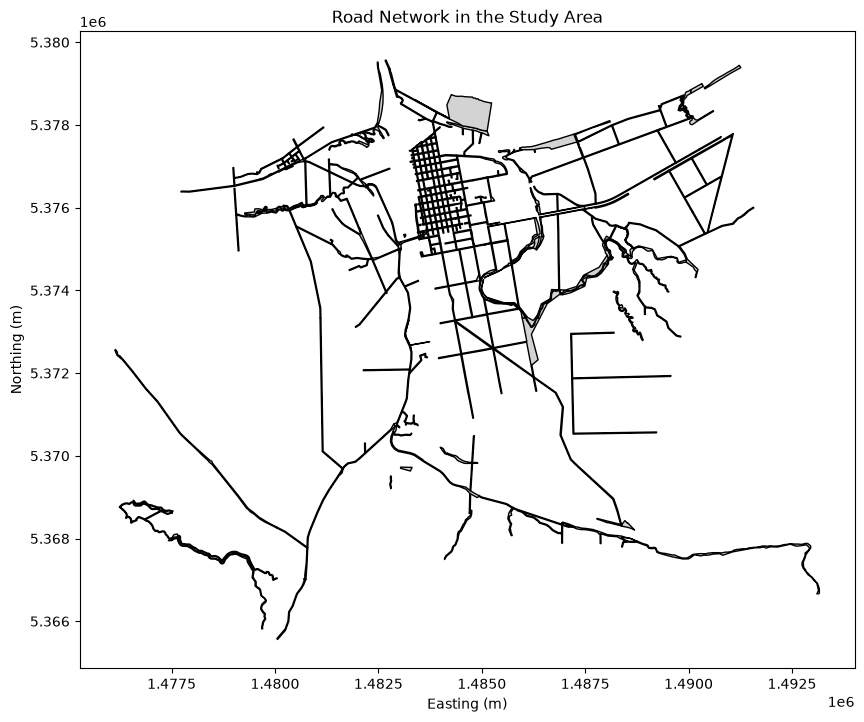

In [2]:
#Visualise the road network
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 10))
roads.plot(ax=ax, color='lightgrey', edgecolor='black')
ax.set_title("Road Network in the Study Area")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.show()

In [ ]:
#Get address point data for the study area using LINZ service (WFS + bbox).

import geopandas as gpd
import rasterio

SIMULATION_DATA_DIR = f"/data/westport/data"
ADDRESS_POINTS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/address_points.gpkg"

DEM_FILE_PATH = f"{SIMULATION_DATA_DIR}/dem/Topo.tif"
LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"

with rasterio.open(DEM_FILE_PATH) as dem_dataset:
    dem_bounds = dem_dataset.bounds
    dem_crs = dem_dataset.crs

print(f"DEM Bounds: {dem_bounds}")
print(f"DEM CRS: {dem_crs}")

# DEM bounds are already in NZTM2000 (EPSG:2193); WFS bbox = minx,miny,maxx,maxy,CRS
bbox_str = f"{dem_bounds.left},{dem_bounds.bottom},{dem_bounds.right},{dem_bounds.top},EPSG:2193"

# NZ Addresses = layer 123113. Same WFS GetFeature + bbox pattern as the building
# and road cells above -- the /services/query/v1/ endpoint is a point+radius
# lookup capped at max_results, so it cannot return every address in the extent.
wfs_url = (
    f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs?"
    f"service=WFS&version=2.0.0&request=GetFeature"
    f"&typeNames=layer-123113"
    f"&bbox={bbox_str}"
    f"&outputFormat=application/json"
)

addresses = gpd.read_file(wfs_url)
print(f"Fetched {len(addresses)} addresses")

# Save the address data to a GeoPackage file
addresses.to_file(ADDRESS_POINTS_FILE_PATH, driver="GPKG")
print(f"Address data saved to {ADDRESS_POINTS_FILE_PATH}")



DEM Bounds: BoundingBox(left=1478882.0, bottom=5367810.8, right=1490478.8, top=5379561.2)
DEM CRS: PROJCS["NZGD2000 / New Zealand Transverse Mercator 2000",GEOGCS["NZGD2000",DATUM["New_Zealand_Geodetic_Datum_2000",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6167"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4167"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",173],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",1600000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","2193"]]
Fetched 3480 addresses
Address data saved to /data/westport/data/exposure/address_points.gpkg


In [2]:
# Building-centred exposure links: one row per building, carrying the property
# it sits on, the address it is known by and the street it is addressed on.
#
# building_id is the primary key -- every building appears exactly once in
# building_links, with NaN plus a *_source column recording how (or whether)
# each link resolved. building_addresses stays a record of where address points
# physically are: one point, one building.
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import geopandas as gpd
import numpy as np
import pandas as pd

from modules.utils.spatial_operators.operators import load_features

SIMULATION_DATA_DIR = "/data/westport/data"
ADDRESS_POINTS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/address_points.gpkg"
BUILDING_FILE_PATH       = f"{SIMULATION_DATA_DIR}/exposure/buildings.gpkg"
PROPERTY_FILE_PATH       = f"{SIMULATION_DATA_DIR}/exposure/property_boundaries.gpkg"
ADDRESS_ROADS_FILE_PATH  = f"{SIMULATION_DATA_DIR}/exposure/address_roads.gpkg"
MANUAL_ADDRESS_POINTS    = f"{SIMULATION_DATA_DIR}/exposure/manual_address_points.csv"
EXCLUDED_BUILDINGS       = f"{SIMULATION_DATA_DIR}/exposure/excluded_buildings.csv"


WORK_CRS = 2193
MAX_ADDR_DIST_M = 15.0   # an address point further away than this is someone else's

addresses  = gpd.read_file(ADDRESS_POINTS_FILE_PATH).to_crs(WORK_CRS)
# Buildings outside the flood model's valid cells have no exposure to compute,
# so they are dropped here rather than carried as permanent NaN. load_features
# is the same domain filter ImpactModule applies.
buildings  = load_features(BUILDING_FILE_PATH).to_crs(WORK_CRS)

# Buildings that no longer exist on the ground -- demolished since the LINZ
# capture. Dropped up front so they take no address, hold no point and never
# reach the exposure table.
if os.path.exists(EXCLUDED_BUILDINGS):
    excluded = pd.read_csv(EXCLUDED_BUILDINGS)
    if len(excluded):
        present = buildings["building_id"].isin(excluded["building_id"])
        buildings = buildings[~present]
        print(f"excluded {int(present.sum())} building(s): "
              + ", ".join(f"{r.building_id} ({r.reason})" for r in excluded.itertuples()))
properties = gpd.read_file(PROPERTY_FILE_PATH).to_crs(WORK_CRS)
roads      = gpd.read_file(ADDRESS_ROADS_FILE_PATH).to_crs(WORK_CRS)

bgeom, ageom, pgeom = buildings.geometry.name, addresses.geometry.name, properties.geometry.name

# Parcels without a unit_of_property_id can never be a building's "property";
# dropping them keeps NaN out of the join keys.
titled = properties[properties["unit_of_property_id"].notna()][
    ["unit_of_property_id", pgeom]
].rename(columns={"unit_of_property_id": "property_id"})

# address_points.road_id is the address_roads road_id, so the street is a
# straight lookup rather than a spatial guess.
street_names = roads[["road_id", "full_road_name"]].drop_duplicates("road_id").rename(
    columns={"full_road_name": "street_name"})

# ── MANUAL OVERRIDES ──────────────────────────────────────────────────────────
# Two kinds of row, told apart by whether address_id already exists in LINZ:
#   * new point     -- blank/negative address_id; a genuine address the extract
#                      lacks. Only building_id and full_address are required.
#   * assignment    -- an existing LINZ address_id plus a building_id: "this
#                      building is at that address too". Applied to the wide
#                      table further down, so the point keeps the building it
#                      physically stands in.

manual_assignments = pd.DataFrame(columns=["building_id", "address_id"])
if os.path.exists(MANUAL_ADDRESS_POINTS):
    manual = pd.read_csv(MANUAL_ADDRESS_POINTS)

    if len(manual) and "address_id" in manual.columns:
        is_existing = manual["address_id"].isin(addresses["address_id"])
        manual_assignments = manual[is_existing][["building_id", "address_id"]].copy()
        manual = manual[~is_existing]
        if len(manual_assignments):
            print(f"{len(manual_assignments)} manual address assignment(s) to apply")

    if len(manual):
        for col in ("address_id", "road_id", "easting", "northing", "building_id"):
            if col not in manual.columns:
                manual[col] = np.nan

        # A blank address_id gets the next free negative one -- negatives never
        # collide with LINZ ids and stay easy to filter back out.
        blank_id = manual["address_id"].isna()
        if blank_id.any():
            start = int(manual["address_id"].min()) - 1 if manual["address_id"].notna().any() else -1
            manual.loc[blank_id, "address_id"] = range(start, start - int(blank_id.sum()), -1)
        manual["address_id"] = manual["address_id"].astype(int)

        # No coordinates? Put the point on the named building's centroid, which
        # also guarantees it links as in_footprint rather than by proximity.
        centroid_by_id = buildings.set_index("building_id")[bgeom].centroid
        need_xy = manual["easting"].isna() | manual["northing"].isna()
        if need_xy.any():
            pts = manual.loc[need_xy, "building_id"].map(centroid_by_id)
            if pts.isna().any():
                raise ValueError("manual rows need easting/northing or an in-domain building_id")
            manual.loc[need_xy, "easting"] = [p.x for p in pts]
            manual.loc[need_xy, "northing"] = [p.y for p in pts]

        # No road_id? Recover it from the street named in the address text.
        need_road = manual["road_id"].isna()
        if need_road.any():
            for i in manual.index[need_road]:
                text = str(manual.at[i, "full_address"]).upper()
                hits = [(len(r.street_name), r.road_id) for r in street_names.itertuples()
                        if str(r.street_name).upper() in text]
                if hits:
                    manual.at[i, "road_id"] = max(hits)[1]

        manual_gdf = gpd.GeoDataFrame(
            manual.drop(columns=["easting", "northing"]),
            geometry=gpd.points_from_xy(manual["easting"], manual["northing"]),
            crs=2193).to_crs(addresses.crs)
        addresses = pd.concat([addresses, manual_gdf], ignore_index=True)
        print(f"added {len(manual)} manual address point(s): "
              f"{', '.join(manual['full_address'].astype(str))}")

links = buildings[["building_id", "use", bgeom]].copy()
print(f"buildings {len(links)} | titled parcels {len(titled)} | "
      f"addresses {len(addresses)} | roads {len(roads)}")

# ── 1. BUILDING -> PROPERTY, by largest overlap ───────────────────────────────
# Deliberately not predicate="within": a footprint straddling a parcel boundary
# is inside no parcel at all and would vanish from a within-join.

cand = gpd.sjoin(links[["building_id", bgeom]], titled,
                 how="inner", predicate="intersects").drop(columns="index_right")
cand = cand.merge(titled.rename(columns={pgeom: "property_geometry"}),
                  on="property_id", how="left")
cand["overlap_area"] = gpd.GeoSeries(cand[bgeom].values, crs=WORK_CRS).intersection(
    gpd.GeoSeries(cand["property_geometry"].values, crs=WORK_CRS)).area
cand["overlap_frac"] = cand["overlap_area"] / cand[bgeom].area.values

building_property = (cand.sort_values("overlap_area", ascending=False)
                         .drop_duplicates("building_id", keep="first")
                         [["building_id", "property_id", "overlap_frac"]])
links = links.merge(building_property, on="building_id", how="left")
links["property_source"] = np.where(links["property_id"].notna(), "max_overlap", "none")

# ── 1b. FALL BACK TO NON-RATING PARCELS ───────────────────────────────────────
# Buildings on Crown land, road reserve or unlabelled parcels have no
# unit_of_property_id, but that parcel is still their grounds, so it is used
# with its LINZ feature id as a surrogate property_id. Only "max_overlap" rows
# carry a real unit_of_property_id.

non_rating = properties[properties["unit_of_property_id"].isna()][
    ["id", pgeom]].rename(columns={"id": "property_id"})

need_property = links["property_id"].isna()
if need_property.any() and not non_rating.empty:
    fb = gpd.sjoin(links.loc[need_property, ["building_id", bgeom]], non_rating,
                   how="inner", predicate="intersects").drop(columns="index_right")
    fb = fb.merge(non_rating.rename(columns={pgeom: "property_geometry"}),
                  on="property_id", how="left")
    fb["overlap_area"] = gpd.GeoSeries(fb[bgeom].values, crs=WORK_CRS).intersection(
        gpd.GeoSeries(fb["property_geometry"].values, crs=WORK_CRS)).area
    fb["overlap_frac"] = fb["overlap_area"] / fb[bgeom].area.values
    fb["src"] = "untitled_land"
    lut = (fb.sort_values("overlap_area", ascending=False)
             .drop_duplicates("building_id", keep="first").set_index("building_id"))
    idx = links.index[need_property]
    for col in ("property_id", "overlap_frac"):
        links.loc[idx, col] = links.loc[idx, "building_id"].map(lut[col]).values
    links.loc[idx, "property_source"] = (
        links.loc[idx, "building_id"].map(lut["src"]).fillna("none").values)
    print("property fallback:\n" + links.loc[idx, "property_source"].value_counts().to_string())
elif need_property.any():
    print(f"{int(need_property.sum())} buildings on no parcel in this property layer")

# ── 2. BUILDING -> ADDRESS ────────────────────────────────────────────────────
# Preference: point inside the footprint, then a building on the point's own
# parcel, and only then the nearest building within MAX_ADDR_DIST_M. Parcel
# before distance matters -- a point near a boundary is often closer to the
# neighbour's house than to anything on its own section.

addr = addresses[["address_id", "full_address", "road_id", ageom]].copy()
parcel_area = titled.set_index("property_id")[pgeom].area

# Tier 1 -- the point sits on a roof.
inside = gpd.sjoin(addr, links[["building_id", bgeom]],
                   how="inner", predicate="within").drop(columns="index_right")
inside = inside.assign(address_source="in_footprint", address_dist_m=0.0)

# Tier 2 -- the point sits on a parcel that has buildings. It goes to the
# building covering most of that parcel; the rest inherit it as shared_parcel.
remaining = addr[~addr["address_id"].isin(inside["address_id"])]
on_parcel = gpd.sjoin(remaining, titled, how="inner", predicate="within").drop(
    columns="index_right")
# Unit and cross-lease titles stack parcels on the same ground, so a point can
# fall inside several; keep the smallest, which is the most specific title.
on_parcel = (on_parcel.assign(_pa=on_parcel["property_id"].map(parcel_area))
             .sort_values("_pa").drop_duplicates("address_id", keep="first")
             .drop(columns="_pa"))

# The parcel's main building, by how much of the parcel it covers -- geometric
# rather than via each building's assigned property_id, so a footprint that
# straddles the boundary can still receive its own parcel's address.
occupants = gpd.sjoin(links[["building_id", bgeom]], titled,
                      how="inner", predicate="intersects").drop(columns="index_right")
occupants = occupants.merge(titled.rename(columns={pgeom: "parcel_geometry"}),
                            on="property_id", how="left")
occupants["_ov"] = gpd.GeoSeries(occupants[bgeom].values, crs=WORK_CRS).intersection(
    gpd.GeoSeries(occupants["parcel_geometry"].values, crs=WORK_CRS)).area
main_on_parcel = (occupants.sort_values(["_ov", "building_id"], ascending=[False, True])
                  .drop_duplicates("property_id", keep="first")
                  [["property_id", "building_id"]])

same_parcel = on_parcel.merge(main_on_parcel, on="property_id", how="inner")
same_parcel["address_dist_m"] = gpd.GeoSeries(
    same_parcel[ageom].values, crs=WORK_CRS).distance(
    gpd.GeoSeries(same_parcel["building_id"].map(
        links.set_index("building_id")[bgeom]).values, crs=WORK_CRS))
same_parcel = same_parcel.assign(address_source="same_parcel")

# Tier 3 -- no parcel, or a parcel with nothing standing on it.
leftover = addr[~addr["address_id"].isin(inside["address_id"])
                & ~addr["address_id"].isin(same_parcel["address_id"])]
near = gpd.sjoin_nearest(
    leftover, links[["building_id", bgeom]],
    how="inner", max_distance=MAX_ADDR_DIST_M, distance_col="address_dist_m",
).drop(columns="index_right").assign(address_source="nearby")

building_addresses = pd.concat(
    [pd.DataFrame(inside.drop(columns=ageom)),
     pd.DataFrame(same_parcel.drop(columns=[ageom, "property_id"])),
     pd.DataFrame(near.drop(columns=ageom))],
    ignore_index=True,
)[["building_id", "address_id", "full_address", "road_id",
   "address_source", "address_dist_m"]]

# A manual assignment whose point no other building has claimed is recorded as a
# real pair, so the long table shows a building that genuinely carries two
# numbers. Only when exactly one building is assigned the address: where several
# share a number no single building owns the point, so those are wide-table only
# and one point still maps to one building.
if len(manual_assignments):
    sole = manual_assignments["address_id"].map(
        manual_assignments.groupby("address_id").size()).eq(1)
    unclaimed = manual_assignments[
        sole & ~manual_assignments["address_id"].isin(building_addresses["address_id"])]
    if len(unclaimed):
        extra = unclaimed.merge(
            addresses[["address_id", "full_address", "road_id", ageom]],
            on="address_id", how="left")
        extra["address_dist_m"] = gpd.GeoSeries(
            extra["building_id"].map(links.set_index("building_id")[bgeom]).values,
            crs=WORK_CRS).distance(gpd.GeoSeries(extra[ageom].values, crs=WORK_CRS)).values
        extra["address_source"] = "manual"
        building_addresses = pd.concat(
            [building_addresses, pd.DataFrame(extra.drop(columns=ageom))],
            ignore_index=True,
        )[["building_id", "address_id", "full_address", "road_id",
           "address_source", "address_dist_m"]]
        print(f"recorded {len(extra)} manual assignment(s) as address-point links")

# One primary address per building for the wide table: best source, then closest.
# A hand assertion outranks anything derived from geometry.
SOURCE_RANK = {"manual": 0, "in_footprint": 1, "same_parcel": 2, "nearby": 3}
primary = (building_addresses.assign(_rank=building_addresses["address_source"].map(SOURCE_RANK))
           .sort_values(["_rank", "address_dist_m", "address_id"])
           .drop_duplicates("building_id", keep="first")
           .drop(columns="_rank"))
n_addr = building_addresses.groupby("building_id").size().rename("n_addresses")

links = links.merge(primary, on="building_id", how="left").merge(n_addr, on="building_id", how="left")
links["n_addresses"] = links["n_addresses"].fillna(0).astype(int)
links["address_source"] = links["address_source"].fillna("none")

# ── 2b. INHERIT THE PARCEL'S ADDRESS ──────────────────────────────────────────
# LINZ issues about one address point per property, not per structure, so on a
# section with a house and a garage the house consumes the only point. For
# exposure the garage genuinely IS at that address, so the wide table inherits
# it, tagged shared_parcel. n_addresses keeps counting only a building's own
# points (0 for an inherited row).
#
# Donors are keyed by the parcel the ADDRESS POINT lies in, not the parcel its
# consuming building was assigned to -- those differ when a footprint straddles
# a boundary, and keying on the consumer left buildings unaddressed on parcels
# that plainly contain a point. No smallest-parcel dedupe: where unit titles
# stack, a point donates to every parcel it falls in.

assigned_pts = addr[addr["address_id"].isin(building_addresses["address_id"])]
pts_parcel = gpd.sjoin(assigned_pts[["address_id", ageom]], titled,
                       how="inner", predicate="within").drop(columns="index_right")

building_area = links.set_index("building_id")[bgeom].area
main_dwelling = (
    building_addresses.merge(pts_parcel[["address_id", "property_id"]], on="address_id")
    .assign(_area=lambda d: d["building_id"].map(building_area))
    .sort_values(["_area", "address_id"], ascending=[False, True])
    .drop_duplicates("property_id", keep="first")
    .set_index("property_id")[["address_id", "full_address", "road_id"]])

needs_address = links["address_id"].isna() & links["property_id"].notna()
inheritable = needs_address & links["property_id"].isin(main_dwelling.index)
for col in ("address_id", "full_address", "road_id"):
    links.loc[inheritable, col] = links.loc[inheritable, "property_id"].map(
        main_dwelling[col]).values
links.loc[inheritable, "address_source"] = "shared_parcel"
print(f"inherited a parcel address for {int(inheritable.sum())} buildings")

# ── 2c. MANUAL ASSIGNMENTS ────────────────────────────────────────────────────
# Hand-asserted "this building is at that address", for cases the geometry can't
# reach. Wide table only, so the point keeps the building it stands in.

if len(manual_assignments):
    point_lookup = addresses.set_index("address_id")
    for row in manual_assignments.itertuples():
        target = links["building_id"] == row.building_id
        if not target.any():
            raise ValueError(f"manual assignment: building {row.building_id} not in the domain")
        point = point_lookup.loc[row.address_id]
        links.loc[target, "address_id"] = row.address_id
        links.loc[target, "full_address"] = point["full_address"]
        links.loc[target, "road_id"] = point["road_id"]
        links.loc[target, "address_source"] = "manual"
        links.loc[target, "address_dist_m"] = (
            links.loc[target, bgeom].distance(point[ageom]).values)

# Buildings with no address point on their own land are left unaddressed rather
# than given a neighbour's address -- a nearby number is a guess about the
# street, not a record of this building.

# ── 3. BUILDING -> STREET ─────────────────────────────────────────────────────
# The addressed street is authoritative where an address exists; the rest fall
# back to the nearest road, flagged and distance-stamped.

links = links.merge(street_names, on="road_id", how="left")
links["street_source"] = np.where(links["street_name"].notna(), "address", "none")
links["street_dist_m"] = np.nan

need = links["street_name"].isna()
if need.any():
    fallback = gpd.sjoin_nearest(
        gpd.GeoDataFrame(links.loc[need, ["building_id"]],
                         geometry=links.loc[need, bgeom].values, crs=WORK_CRS),
        roads[["road_id", "full_road_name", roads.geometry.name]].rename(
            columns={"full_road_name": "street_name"}),
        how="left", distance_col="street_dist_m").drop(columns="index_right")
    fallback = fallback.sort_values("street_dist_m").drop_duplicates("building_id").set_index("building_id")
    idx = links.index[need]
    for col in ("road_id", "street_name", "street_dist_m"):
        links.loc[idx, col] = links.loc[idx, "building_id"].map(fallback[col]).values
    links.loc[idx, "street_source"] = "nearest_road"

# ── TEMPLATE FOR MANUAL ADDRESSING ────────────────────────────────────────────
# Buildings still without an address, in the exact shape of
# MANUAL_ADDRESS_POINTS. For a NEW address type full_address and address_number
# and paste the row across; to reuse an EXISTING LINZ address instead, put its
# address_id in the address_id column and leave the rest blank.

todo = links[links["address_id"].isna()].copy()
if len(todo):
    existing_manual = (pd.read_csv(MANUAL_ADDRESS_POINTS)
                       if os.path.exists(MANUAL_ADDRESS_POINTS)
                       else pd.DataFrame(columns=["address_id"]))
    next_id = int(existing_manual["address_id"].min()) - 1 if len(existing_manual) else -1
    centroids = todo[bgeom].centroid
    hint = gpd.sjoin_nearest(
        gpd.GeoDataFrame(todo[["building_id"]], geometry=centroids.values, crs=WORK_CRS),
        addresses[["address_id", "full_address", ageom]],
        how="left", distance_col="nearest_address_m").drop(columns="index_right")
    hint = (hint.sort_values("nearest_address_m")
                .drop_duplicates("building_id").set_index("building_id"))
    buildings_needing_address = pd.DataFrame({
        "address_id": range(next_id, next_id - len(todo), -1),
        "full_address": "", "road_id": todo["road_id"].values, "address_number": "",
        "easting": centroids.x.round(1).values, "northing": centroids.y.round(1).values,
        "note": ["building " + str(b) for b in todo["building_id"]],
        "building_id": todo["building_id"].values,
        "use": todo["use"].values,
        "property_id": todo["property_id"].values,
        "nearest_address_id": todo["building_id"].map(hint["address_id"]).values,
        "nearest_address": todo["building_id"].map(hint["full_address"]).values,
        "nearest_address_m": todo["building_id"].map(hint["nearest_address_m"]).round(1).values,
    })
    print(f"{len(buildings_needing_address)} buildings still need an address "
          f"-- see the buildings_needing_address frame")
else:
    buildings_needing_address = pd.DataFrame()

# ── RESULT ────────────────────────────────────────────────────────────────────

building_links = links[["building_id", "use",
                        "property_id", "property_source", "overlap_frac",
                        "address_id", "full_address", "address_source",
                        "address_dist_m", "n_addresses",
                        "road_id", "street_name", "street_source", "street_dist_m"]]
assert building_links["building_id"].is_unique, "building_id must be the primary key"
assert building_addresses.groupby("address_id")["building_id"].nunique().le(1).all(), \
    "an address point must map to exactly one building"

n = len(building_links)
print(f"\none row per building: {n} rows, {len(building_addresses)} building-address pairs")
for col, label in (("property_id", "property"), ("address_id", "address"),
                   ("street_name", "street")):
    have = int(building_links[col].notna().sum())
    print(f"  {label:9} {have:5} / {n}  ({have / n:.1%})")
print("\naddress_source:\n" + building_links["address_source"].value_counts().to_string())
print("\nstreet_source:\n" + building_links["street_source"].value_counts().to_string())
print("\nbuildings with >1 address:", int((building_links["n_addresses"] > 1).sum()))

building_links.head(10)


excluded 1 building(s): 2541342 (demolished)
48 manual address assignment(s) to apply
added 2 manual address point(s): 36 Kew Road, Westport, 44 Cobden Street, Westport
buildings 5555 | titled parcels 3437 | addresses 3482 | roads 130
87 buildings on no parcel in this property layer
recorded 2 manual assignment(s) as address-point links
inherited a parcel address for 2696 buildings
105 buildings still need an address -- see the buildings_needing_address frame

one row per building: 5555 rows, 3105 building-address pairs
  property   5468 / 5555  (98.4%)
  address    5450 / 5555  (98.1%)
  street     5555 / 5555  (100.0%)

address_source:
address_source
shared_parcel    2695
in_footprint     1626
same_parcel      1068
none              105
manual             48
nearby             13

street_source:
street_source
address         5450
nearest_road     105

buildings with >1 address: 276


,building_id,use,property_id,property_source,overlap_frac,address_id,full_address,address_source,address_dist_m,n_addresses,road_id,street_name,street_source,street_dist_m
0,2522712,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,0.767949,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
1,2522716,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
2,2522715,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
3,2515187,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
4,2515202,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
5,2515203,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
6,2515204,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
7,2515201,Unknown,608d4647-3e93-4aff-86cc-2ac6a81e8280,max_overlap,1.000000,1626483.0,"55 Bradshaws Road, Carters Beach, Westport",same_parcel,10.961478,1,1787932.0,Bradshaws Road,address,NaN
8,2515205,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN
9,2522713,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,max_overlap,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_parcel,NaN,0,1787932.0,Bradshaws Road,address,NaN


In [10]:
#Buildings without a property
buildings_without_property = building_links[building_links["property_id"].isna()]
print(f"Buildings without a property: {len(buildings_without_property)}")

#buildings without an address
buildings_without_address = building_links[building_links["address_id"].isna()]
print(f"Buildings without an address: {len(buildings_without_address)}")

Buildings without a property: 87
Buildings without an address: 110


In [1]:
# LINZ's authoritative property references, cut down to the computational domain.
#
# Both are hosted as tables: three columns each, no geometry, so a WFS bbox is
# rejected outright. The domain filter therefore happens locally -- the parcels
# intersecting the flood domain are identified first, and their property ids are
# sent back as CQL filters in chunks small enough to keep each GET under the URL
# length limit.
#
# These say outright what the geometric cascade has been inferring: which
# buildings and which addresses belong to which property.
import json
import os
import sys
import urllib.parse
import urllib.request

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
from rasterio import features as rio_features
from shapely.geometry import shape
from shapely.ops import unary_union

from modules.utils.spatial_operators.operators import find_sample_flood_map

VALUATION_BUILDING_REFERENCE_LINK = "https://data.linz.govt.nz/services;key=a06a74b6c02f4d4a81f999bd09034897/wfs/table-119620/?service=WFS&request=GetCapabilities"

PROPERY_ADDRESS_REFERNECE = "https://data.linz.govt.nz/services;key=a06a74b6c02f4d4a81f999bd09034897/wfs/table-115638/?service=WFS&request=GetCapabilities"

# property attributes
NZ_PROPERZTIES = "https://data.linz.govt.nz/services;key=a06a74b6c02f4d4a81f999bd09034897/wfs/table-114085/?service=WFS&request=GetCapabilities"

SIMULATION_DATA_DIR = "/data/westport/data"
EXPOSURE_DIR = f"{SIMULATION_DATA_DIR}/exposure"
PROPERTY_FILE_PATH = f"{EXPOSURE_DIR}/property_boundaries.gpkg"
PROPERTY_ADDRESSES_PATH = f"{EXPOSURE_DIR}/property_addresses.csv"
PROPERTY_BUILDINGS_PATH = f"{EXPOSURE_DIR}/property_buildings_reference.csv"
PROPERTY_ATTRIBUTES_PATH = f"{EXPOSURE_DIR}/property_attributes.csv"

LINZ_KEY = "a06a74b6c02f4d4a81f999bd09034897"
WFS = f"https://data.linz.govt.nz/services;key={LINZ_KEY}/wfs"

# table id -> (output file, the column paired with unit_of_property_id)
REFERENCES = {
    "table-115638": (PROPERTY_ADDRESSES_PATH, "address_id"),    # Property-Address
    "table-119620": (PROPERTY_BUILDINGS_PATH, "building_id"),   # Property-Building
}

WORK_CRS = 2193
CHUNK = 100          # ~4 kB of UUIDs per request
REFRESH = False      # True to re-download tables already on disk

# ── PARCELS INSIDE THE COMPUTATIONAL DOMAIN ───────────────────────────────────
# Same ~isnan mask load_features uses, polygonised so parcels can be tested
# against it directly.

with rasterio.open(find_sample_flood_map()) as src:
    _mask = (~np.isnan(src.read(1).astype("float32"))).astype("uint8")
    _polys = [shape(g) for g, v in rio_features.shapes(
        _mask, mask=_mask.astype(bool), transform=src.transform) if v == 1]
    _domain_crs = src.crs
domain = gpd.GeoSeries([unary_union(_polys)], crs=_domain_crs).to_crs(WORK_CRS).iloc[0].simplify(10)

parcels = gpd.read_file(PROPERTY_FILE_PATH).to_crs(WORK_CRS)
parcels_in_domain = parcels[parcels.intersects(domain)]
property_ids = sorted(parcels_in_domain["unit_of_property_id"].dropna().unique())
print(f"domain {domain.area / 1e6:.1f} km2 | parcels {len(parcels_in_domain)} of {len(parcels)} "
      f"| property ids {len(property_ids)}")

# ── FETCH ─────────────────────────────────────────────────────────────────────


def fetch_reference(type_name, value_col, ids, chunk=CHUNK):
    """Every (unit_of_property_id, value_col) row for these property ids."""
    rows = []
    for start in range(0, len(ids), chunk):
        quoted = ",".join("'" + i.replace("'", "''") + "'" for i in ids[start:start + chunk])
        params = {
            "service": "WFS", "version": "2.0.0", "request": "GetFeature",
            "typeNames": type_name, "outputFormat": "application/json",
            "CQL_FILTER": f"unit_of_property_id IN ({quoted})",
        }
        with urllib.request.urlopen(f"{WFS}?{urllib.parse.urlencode(params)}", timeout=300) as r:
            payload = json.load(r)
        if "features" not in payload:
            raise RuntimeError(f"unexpected WFS response: {str(payload)[:300]}")
        rows.extend(f["properties"] for f in payload["features"])
        print(f"    {min(start + chunk, len(ids)):5}/{len(ids)} ids -> {len(rows)} rows", flush=True)
    out = pd.DataFrame.from_records(rows)[["unit_of_property_id", value_col]]
    return out.drop_duplicates().sort_values(["unit_of_property_id", value_col])


for type_name, (out_path, value_col) in REFERENCES.items():
    if os.path.exists(out_path) and not REFRESH:
        existing = pd.read_csv(out_path)
        print(f"[skip] {type_name}: {out_path} already has {len(existing)} rows")
        continue
    print(f"[get]  {type_name} -> {value_col}")
    table = fetch_reference(type_name, value_col, property_ids)
    table.to_csv(out_path, index=False)
    print(f"[ok]   wrote {out_path}: {len(table)} rows")

# ── WHAT WE HAVE ──────────────────────────────────────────────────────────────

property_addresses = pd.read_csv(PROPERTY_ADDRESSES_PATH)
property_buildings = pd.read_csv(PROPERTY_BUILDINGS_PATH)

for name, df, col in (("addresses", property_addresses, "address_id"),
                      ("buildings", property_buildings, "building_id")):
    n_prop = df["unit_of_property_id"].nunique()
    per = df.groupby("unit_of_property_id").size()
    print(f"\nproperty -> {name}: {len(df)} links, {n_prop} properties "
          f"({n_prop / len(property_ids):.1%} of in-domain)")
    print(f"  per property: median {per.median():.0f}, max {per.max()}")
    shared = df.groupby(col).size()
    print(f"  {col} referenced against >1 property: {int((shared > 1).sum())}")


# ── PROPERTY ATTRIBUTES (District Valuation Roll) ─────────────────────────────
# table-114085 is the valuation roll: capital_value, land_value, floor area,
# bedrooms and so on, keyed on unit_of_property_id like the references above.
# Fetched the same way -- but note it is only as national as the councils that
# supply it, and Buller is not among them: every Westport street and every
# in-domain property id comes back empty. The block is left in place so the file
# appears the moment that changes.

ATTRIBUTE_COLS = ["unit_of_property_id", "valuation_no_roll", "valuation_no_assessment",
                  "capital_value", "land_value", "improvements_value",
                  "building_total_floor_area", "no_of_bedrooms", "actual_property_use",
                  "property_category", "land_area", "situation_number", "situation_name",
                  "legal_description", "district_ta_code"]

if os.path.exists(PROPERTY_ATTRIBUTES_PATH) and not REFRESH:
    print(f"\n[skip] table-114085: {PROPERTY_ATTRIBUTES_PATH} already exists")
else:
    print("\n[get]  table-114085 -> property attributes")
    rows = []
    for _start in range(0, len(property_ids), CHUNK):
        _quoted = ",".join("'" + i.replace("'", "''") + "'"
                           for i in property_ids[_start:_start + CHUNK])
        _params = {
            "service": "WFS", "version": "2.0.0", "request": "GetFeature",
            "typeNames": "table-114085", "outputFormat": "application/json",
            "CQL_FILTER": f"unit_of_property_id IN ({_quoted})",
        }
        with urllib.request.urlopen(f"{WFS}?{urllib.parse.urlencode(_params)}", timeout=300) as r:
            _payload = json.load(r)
        rows.extend(f["properties"] for f in _payload.get("features", []))
    if rows:
        attributes = pd.DataFrame.from_records(rows)
        keep = [c for c in ATTRIBUTE_COLS if c in attributes.columns]
        attributes[keep].to_csv(PROPERTY_ATTRIBUTES_PATH, index=False)
        print(f"[ok]   wrote {PROPERTY_ATTRIBUTES_PATH}: {len(attributes)} rows")
    else:
        print("[none] the valuation roll holds no records for these properties -- "
              "Buller District does not supply this dataset, so nothing is written")


domain 53.1 km2 | parcels 3167 of 3437 | property ids 3167
[skip] table-115638: /data/westport/data/exposure/property_addresses.csv already has 3344 rows
[skip] table-119620: /data/westport/data/exposure/property_buildings_reference.csv already has 5886 rows

property -> addresses: 3344 links, 2961 properties (93.5% of in-domain)
  per property: median 1, max 23
  address_id referenced against >1 property: 42

property -> buildings: 5886 links, 2828 properties (89.3% of in-domain)
  per property: median 2, max 20
  building_id referenced against >1 property: 148

[get]  table-114085 -> property attributes
[none] the valuation roll holds no records for these properties -- Buller District does not supply this dataset, so nothing is written


In [1]:
# Reference-first exposure links: one row per building, carrying the property it
# belongs to, the address it is known by and the street it is addressed on.
#
# LINZ's own association tables decide membership wherever they cover it --
# property_buildings_reference says which buildings belong to a property,
# property_addresses says which addresses do. Geometry is demoted to the two
# jobs those tables cannot do: choosing WHICH building on a property takes WHICH
# address point, and filling the gaps where the references are silent. Every
# link carries a *_source column saying which authority produced it.
import os
import sys

PROJECT_ROOT = "/home/91/23016891/projects/westport-ibw"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import geopandas as gpd
import numpy as np
import pandas as pd

from modules.utils.spatial_operators.operators import load_features

SIMULATION_DATA_DIR = "/data/westport/data"
BUILDING_FILE_PATH  = f"{SIMULATION_DATA_DIR}/exposure/buildings.gpkg"
PROPERTY_BUILDING_REFERENCE_PATH = f"{SIMULATION_DATA_DIR}/exposure/property_buildings_reference.csv"
PROPERTY_FILE_PATH       = f"{SIMULATION_DATA_DIR}/exposure/property_boundaries.gpkg"
PROPERTY_ADDRESS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/property_addresses.csv"
ADDRESS_ROADS_FILE_PATH  = f"{SIMULATION_DATA_DIR}/exposure/address_roads.gpkg"
MANUAL_ADDRESS_POINTS    = f"{SIMULATION_DATA_DIR}/exposure/manual_address_points.csv"
ADDRESS_POINTS_FILE_PATH = f"{SIMULATION_DATA_DIR}/exposure/address_points.gpkg"
EXCLUDED_BUILDINGS       = f"{SIMULATION_DATA_DIR}/exposure/excluded_buildings.csv"
ROAD_CADASTRAL           = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
ROAD_PARCEL_SECTIONS     = f"{SIMULATION_DATA_DIR}/exposure/road_parcel_sections.csv"

WORK_CRS = 2193
MAX_ADDR_DIST_M = 15.0   # geometric fallback only: further than this is someone else's

# ── LOAD ──────────────────────────────────────────────────────────────────────

addresses  = gpd.read_file(ADDRESS_POINTS_FILE_PATH).to_crs(WORK_CRS)
buildings  = load_features(BUILDING_FILE_PATH).to_crs(WORK_CRS)
properties = gpd.read_file(PROPERTY_FILE_PATH).to_crs(WORK_CRS)
roads      = gpd.read_file(ADDRESS_ROADS_FILE_PATH).to_crs(WORK_CRS)
ref_buildings = pd.read_csv(PROPERTY_BUILDING_REFERENCE_PATH)
ref_addresses = pd.read_csv(PROPERTY_ADDRESS_FILE_PATH)

if os.path.exists(EXCLUDED_BUILDINGS):
    excluded = pd.read_csv(EXCLUDED_BUILDINGS)
    if len(excluded):
        gone = buildings["building_id"].isin(excluded["building_id"])
        buildings = buildings[~gone]
        print(f"excluded {int(gone.sum())} building(s): "
              + ", ".join(f"{r.building_id} ({r.reason})" for r in excluded.itertuples()))

bgeom, ageom, pgeom = buildings.geometry.name, addresses.geometry.name, properties.geometry.name

titled = properties[properties["unit_of_property_id"].notna()][
    ["unit_of_property_id", pgeom]].rename(columns={"unit_of_property_id": "property_id"})
street_names = roads[["road_id", "full_road_name"]].drop_duplicates("road_id").rename(
    columns={"full_road_name": "street_name"})

ref_buildings = ref_buildings.rename(columns={"unit_of_property_id": "property_id"})
ref_addresses = ref_addresses.rename(columns={"unit_of_property_id": "property_id"})

links = buildings[["building_id", "use", bgeom]].copy()
print(f"buildings {len(links)} | parcels {len(titled)} | addresses {len(addresses)} "
      f"| ref: {len(ref_buildings)} building links, {len(ref_addresses)} address links")

# ── MANUAL OVERRIDES ──────────────────────────────────────────────────────────
# Hand-entered rows outrank every automatic rule. Two kinds, told apart by
# whether address_id already exists in LINZ: a new point (blank/negative id,
# placed on the named building's centroid) or an assignment of an existing
# address to a building.

manual_assignments = pd.DataFrame(columns=["building_id", "address_id"])
if os.path.exists(MANUAL_ADDRESS_POINTS):
    manual = pd.read_csv(MANUAL_ADDRESS_POINTS)
    if len(manual) and "address_id" in manual.columns:
        is_existing = manual["address_id"].isin(addresses["address_id"])
        manual_assignments = manual[is_existing][["building_id", "address_id"]].copy()
        manual = manual[~is_existing]
    if len(manual):
        for col in ("address_id", "road_id", "easting", "northing", "building_id"):
            if col not in manual.columns:
                manual[col] = np.nan
        blank = manual["address_id"].isna()
        if blank.any():
            start = int(manual["address_id"].min()) - 1 if manual["address_id"].notna().any() else -1
            manual.loc[blank, "address_id"] = range(start, start - int(blank.sum()), -1)
        manual["address_id"] = manual["address_id"].astype(int)

        centroid_by_id = buildings.set_index("building_id")[bgeom].centroid
        need_xy = manual["easting"].isna() | manual["northing"].isna()
        if need_xy.any():
            pts = manual.loc[need_xy, "building_id"].map(centroid_by_id)
            if pts.isna().any():
                raise ValueError("manual rows need easting/northing or an in-domain building_id")
            manual.loc[need_xy, "easting"] = [p.x for p in pts]
            manual.loc[need_xy, "northing"] = [p.y for p in pts]

        need_road = manual["road_id"].isna()
        for i in manual.index[need_road]:
            text = str(manual.at[i, "full_address"]).upper()
            hits = [(len(r.street_name), r.road_id) for r in street_names.itertuples()
                    if str(r.street_name).upper() in text]
            if hits:
                manual.at[i, "road_id"] = max(hits)[1]

        addresses = pd.concat([addresses, gpd.GeoDataFrame(
            manual.drop(columns=["easting", "northing"]),
            geometry=gpd.points_from_xy(manual["easting"], manual["northing"]),
            crs=2193).to_crs(addresses.crs)], ignore_index=True)
        print(f"added {len(manual)} manual address point(s), "
              f"{len(manual_assignments)} manual assignment(s) to apply")

addr = addresses[["address_id", "full_address", "road_id", ageom]].copy()

# ── 1. BUILDING -> PROPERTY ───────────────────────────────────────────────────
# The reference is authoritative. It is many-to-many -- 148 buildings are listed
# against more than one property -- so where it offers several, geometry breaks
# the tie on largest overlap, which is the only way to say which parcel the
# footprint actually sits on.

overlap_area = gpd.sjoin(links[["building_id", bgeom]], titled,
                         how="inner", predicate="intersects").drop(columns="index_right")
overlap_area = overlap_area.merge(
    titled.rename(columns={pgeom: "parcel_geometry"}), on="property_id", how="left")
overlap_area["overlap_area"] = gpd.GeoSeries(overlap_area[bgeom].values, crs=WORK_CRS).intersection(
    gpd.GeoSeries(overlap_area["parcel_geometry"].values, crs=WORK_CRS)).area
overlap_area["overlap_frac"] = overlap_area["overlap_area"] / overlap_area[bgeom].area.values
overlap_lookup = overlap_area.set_index(["building_id", "property_id"])["overlap_frac"]

referenced = ref_buildings[ref_buildings["building_id"].isin(links["building_id"])].copy()
referenced["overlap_frac"] = pd.MultiIndex.from_frame(
    referenced[["building_id", "property_id"]]).map(overlap_lookup)

# Where a building is listed against several properties they are usually unit or
# cross-lease titles stacked on the same ground, so overlap is identical for all
# of them and cannot choose. Prefer the one that carries an address: it is the
# title the property is actually known by, and it keeps the property and address
# columns talking about the same parcel. Overlap only breaks what is left.
addressed_properties = set(ref_addresses["property_id"])
referenced["has_address"] = referenced["property_id"].isin(addressed_properties)

_candidates = referenced.groupby("building_id")["property_id"].size()
_multi = set(_candidates[_candidates > 1].index)
_addressed_per_building = (referenced[referenced["building_id"].isin(_multi)]
                           .groupby("building_id")["has_address"].sum())
print(f"buildings listed against >1 property: {len(_multi)} "
      f"({int((_addressed_per_building == 1).sum())} settled by a single addressed "
      f"property, {int((_addressed_per_building == 0).sum())} with none addressed, "
      f"{int((_addressed_per_building > 1).sum())} with several)")

# Then the smallest parcel, which is the most specific title where several are
# stacked, and finally property_id so the choice is at least deterministic --
# for genuinely identical stacked titles nothing in the data can separate them.
referenced["parcel_area"] = referenced["property_id"].map(
    titled.set_index("property_id")[pgeom].area)
by_reference = (referenced.sort_values(
                    ["has_address", "overlap_frac", "parcel_area", "property_id"],
                    ascending=[False, False, True, True], na_position="last")
                .drop_duplicates("building_id", keep="first")
                [["building_id", "property_id", "overlap_frac"]])
by_reference["property_source"] = "linz_reference"

# Buildings the reference does not mention fall back to largest overlap.
missing = links[~links["building_id"].isin(by_reference["building_id"])]["building_id"]
by_geometry = (overlap_area[overlap_area["building_id"].isin(missing)]
               .sort_values("overlap_area", ascending=False)
               .drop_duplicates("building_id", keep="first")
               [["building_id", "property_id", "overlap_frac"]])
by_geometry["property_source"] = "max_overlap"

building_property = pd.concat([by_reference, by_geometry], ignore_index=True)
links = links.merge(building_property, on="building_id", how="left")
links["property_source"] = links["property_source"].fillna("none")
print("\nproperty_source:\n" + links["property_source"].value_counts().to_string())

# ── 2. BUILDING -> ADDRESS ────────────────────────────────────────────────────
# The reference gives each property its addresses; geometry only decides which
# building on that property holds which point. A point inside a footprint goes
# to that building, otherwise to the nearest building on the same property.

prop_of_building = links.set_index("building_id")["property_id"]
geom_of_building = links.set_index("building_id")[bgeom]

candidates = (ref_addresses.merge(links[["building_id", "property_id"]].dropna(),
                                  on="property_id", how="inner")
              .merge(addr, on="address_id", how="inner"))
if len(candidates):
    candidates["dist"] = gpd.GeoSeries(
        candidates["building_id"].map(geom_of_building).values, crs=WORK_CRS).distance(
        gpd.GeoSeries(candidates[ageom].values, crs=WORK_CRS)).values
    candidates["inside"] = candidates["dist"] <= 1e-6
    # Closest building on the property wins the point; a point standing inside a
    # footprint always wins over one that is merely nearby.
    holder = (candidates.sort_values(["inside", "dist"], ascending=[False, True])
              .drop_duplicates("address_id", keep="first"))
    holder["address_source"] = np.where(holder["inside"], "reference_in_footprint", "reference")
    reference_pairs = holder[["building_id", "address_id", "full_address", "road_id",
                              "address_source", "dist"]].rename(columns={"dist": "address_dist_m"})
else:
    reference_pairs = pd.DataFrame(columns=["building_id", "address_id", "full_address",
                                            "road_id", "address_source", "address_dist_m"])

# Points the reference never places -- their property is not in the table, or
# they belong to a property with no building here. Geometry takes over: inside a
# footprint first, then the nearest building within MAX_ADDR_DIST_M.
unplaced = addr[~addr["address_id"].isin(reference_pairs["address_id"])]
inside = gpd.sjoin(unplaced, links[["building_id", bgeom]],
                   how="inner", predicate="within").drop(columns="index_right")
inside = inside.assign(address_source="in_footprint", address_dist_m=0.0)

leftover = unplaced[~unplaced["address_id"].isin(inside["address_id"])]
near = gpd.sjoin_nearest(leftover, links[["building_id", bgeom]], how="inner",
                         max_distance=MAX_ADDR_DIST_M, distance_col="address_dist_m",
                         ).drop(columns="index_right").assign(address_source="nearby")

building_addresses = pd.concat(
    [reference_pairs,
     pd.DataFrame(inside.drop(columns=ageom)),
     pd.DataFrame(near.drop(columns=ageom))],
    ignore_index=True,
)[["building_id", "address_id", "full_address", "road_id", "address_source", "address_dist_m"]]
building_addresses["building_id"] = building_addresses["building_id"].astype("int64")

# A manual assignment whose point no other building has claimed is recorded as a
# real pair; where several buildings share one number the point stays with its
# holder and the assignment applies to the wide table only.
if len(manual_assignments):
    # Only for buildings the references left without an address: a hand entry is
    # there to fill a gap, not to argue with LINZ.
    already = set(building_addresses["building_id"])
    sole = manual_assignments["address_id"].map(
        manual_assignments.groupby("address_id").size()).eq(1)
    unclaimed = manual_assignments[
        sole & ~manual_assignments["address_id"].isin(building_addresses["address_id"])
        & ~manual_assignments["building_id"].isin(already)]
    if len(unclaimed):
        extra = unclaimed.merge(addr, on="address_id", how="left")
        extra["address_dist_m"] = gpd.GeoSeries(
            extra["building_id"].map(geom_of_building).values, crs=WORK_CRS).distance(
            gpd.GeoSeries(extra[ageom].values, crs=WORK_CRS)).values
        extra["address_source"] = "manual"
        building_addresses = pd.concat(
            [building_addresses, pd.DataFrame(extra.drop(columns=ageom))], ignore_index=True
        )[["building_id", "address_id", "full_address", "road_id",
           "address_source", "address_dist_m"]]

# The references outrank a hand entry; manual only fills what they leave empty.
SOURCE_RANK = {"reference_in_footprint": 0, "reference": 1, "in_footprint": 2,
               "manual": 3, "nearby": 4}
primary = (building_addresses.assign(_rank=building_addresses["address_source"].map(SOURCE_RANK))
           .sort_values(["_rank", "address_dist_m", "address_id"])
           .drop_duplicates("building_id", keep="first").drop(columns="_rank"))
n_addr = building_addresses.groupby("building_id").size().rename("n_addresses")

links = links.merge(primary, on="building_id", how="left").merge(n_addr, on="building_id", how="left")
links["n_addresses"] = links["n_addresses"].fillna(0).astype(int)
links["address_source"] = links["address_source"].fillna("none")

# ── 2b. MANUAL ASSIGNMENTS ────────────────────────────────────────────────────
# Applied only where nothing authoritative reached the building, so the hand
# list fills gaps rather than overriding LINZ. They still beat the inherited
# address below, being a statement about this building rather than its parcel.

if len(manual_assignments):
    point_lookup = addresses.set_index("address_id")
    applied = superseded = 0
    for row in manual_assignments.itertuples():
        target = links["building_id"] == row.building_id
        if not target.any():
            continue
        if links.loc[target, "address_id"].notna().all():
            superseded += 1
            continue
        point = point_lookup.loc[row.address_id]
        links.loc[target, "address_id"] = row.address_id
        links.loc[target, "full_address"] = point["full_address"]
        links.loc[target, "road_id"] = point["road_id"]
        links.loc[target, "address_source"] = "manual"
        links.loc[target, "address_dist_m"] = links.loc[target, bgeom].distance(point[ageom]).values
        applied += 1
    print(f"manual assignments: {applied} applied, {superseded} already addressed "
          f"by the references")

# ── 2c. SHARE THE PROPERTY'S ADDRESS ──────────────────────────────────────────
# LINZ issues about one address per property, not per structure, so the garage
# behind the house gets nothing of its own. For exposure it genuinely is at that
# address, so it inherits the address of the largest addressed building on its
# property. n_addresses keeps counting only a building's own points.

addressed = links[links["address_id"].notna() & links["property_id"].notna()]
donor = (addressed.assign(_area=addressed[bgeom].area)
         .sort_values(["_area", "address_id"], ascending=[False, True])
         .drop_duplicates("property_id", keep="first")
         .set_index("property_id")[["address_id", "full_address", "road_id"]])
share = (links["address_id"].isna() & links["property_id"].notna()
         & links["property_id"].isin(donor.index))
for col in ("address_id", "full_address", "road_id"):
    links.loc[share, col] = links.loc[share, "property_id"].map(donor[col]).values
links.loc[share, "address_source"] = "shared_property"
print(f"shared a property address with {int(share.sum())} buildings")

# ── 3. BUILDING -> STREET ─────────────────────────────────────────────────────
# The addressed street is a lookup on the address's own road_id; only buildings
# with no address at all fall back to the nearest road, flagged and stamped with
# the distance.

links = links.merge(street_names, on="road_id", how="left")
links["street_source"] = np.where(links["street_name"].notna(), "address", "none")
links["street_dist_m"] = np.nan

need = links["street_name"].isna()
if need.any():
    fallback = gpd.sjoin_nearest(
        gpd.GeoDataFrame(links.loc[need, ["building_id"]],
                         geometry=links.loc[need, bgeom].values, crs=WORK_CRS),
        roads[["road_id", "full_road_name", roads.geometry.name]].rename(
            columns={"full_road_name": "street_name"}),
        how="left", distance_col="street_dist_m").drop(columns="index_right")
    fallback = fallback.sort_values("street_dist_m").drop_duplicates("building_id").set_index("building_id")
    idx = links.index[need]
    for col in ("road_id", "street_name", "street_dist_m"):
        links.loc[idx, col] = links.loc[idx, "building_id"].map(fallback[col]).values
    links.loc[idx, "street_source"] = "nearest_road"

# ── 4. BUILDING -> ROAD PARCEL ────────────────────────────────────────────────
# The street gives a name; the exposure model needs the cadastral parcel that
# carries it, since that is the object the flood depth is measured over. Road
# parcels and streets share no key, so they are bridged by the road sections
# (road_parcel_sections.csv): a building takes the parcel of ITS street that
# lies closest to it, rather than whatever parcel happens to be nearest.

road_parcels = gpd.read_file(ROAD_CADASTRAL).to_crs(WORK_CRS)
parcel_streets = pd.read_csv(ROAD_PARCEL_SECTIONS)[
    ["road_parcel_id", "road_id"]].drop_duplicates()
road_parcel_geom = road_parcels.set_index("id").geometry

candidates = links[["building_id", "road_id", bgeom]].merge(
    parcel_streets, on="road_id", how="inner")
if len(candidates):
    candidates["road_parcel_dist_m"] = gpd.GeoSeries(
        candidates[bgeom].values, crs=WORK_CRS).distance(
        gpd.GeoSeries(candidates["road_parcel_id"].map(road_parcel_geom).values,
                      crs=WORK_CRS)).values
    on_street = (candidates.sort_values("road_parcel_dist_m")
                 .drop_duplicates("building_id", keep="first")
                 .set_index("building_id"))
    links["road_parcel_id"] = links["building_id"].map(on_street["road_parcel_id"])
    links["road_parcel_dist_m"] = links["building_id"].map(on_street["road_parcel_dist_m"])
    links["road_parcel_source"] = np.where(links["road_parcel_id"].notna(),
                                           "street_match", "none")
else:
    links["road_parcel_id"] = np.nan
    links["road_parcel_dist_m"] = np.nan
    links["road_parcel_source"] = "none"

# A building whose street carries no parcel falls back to the nearest road
# parcel of any street, flagged so the weaker link stays visible.
need_parcel = links["road_parcel_id"].isna()
if need_parcel.any():
    nearest = gpd.sjoin_nearest(
        gpd.GeoDataFrame(links.loc[need_parcel, ["building_id"]],
                         geometry=links.loc[need_parcel, bgeom].values, crs=WORK_CRS),
        road_parcels[["id", "geometry"]].rename(columns={"id": "road_parcel_id"}),
        how="left", distance_col="road_parcel_dist_m").drop(columns="index_right")
    nearest = (nearest.sort_values("road_parcel_dist_m")
               .drop_duplicates("building_id").set_index("building_id"))
    idx = links.index[need_parcel]
    for col in ("road_parcel_id", "road_parcel_dist_m"):
        links.loc[idx, col] = links.loc[idx, "building_id"].map(nearest[col]).values
    links.loc[idx, "road_parcel_source"] = "nearest_parcel"

print("\nroad_parcel_source:\n" + links["road_parcel_source"].value_counts().to_string())
print(f"distance to the assigned road parcel: "
      f"median {links['road_parcel_dist_m'].median():.1f} m, "
      f"p90 {links['road_parcel_dist_m'].quantile(0.9):.1f} m, "
      f"max {links['road_parcel_dist_m'].max():.0f} m")

# ── RESULT ────────────────────────────────────────────────────────────────────

building_links = links[["building_id", "use",
                        "property_id", "property_source", "overlap_frac",
                        "address_id", "full_address", "address_source",
                        "address_dist_m", "n_addresses",
                        "road_id", "street_name", "street_source", "street_dist_m",
                        "road_parcel_id", "road_parcel_source", "road_parcel_dist_m"]]
assert building_links["building_id"].is_unique, "building_id must be the primary key"
assert building_addresses.groupby("address_id")["building_id"].nunique().le(1).all(), \
    "an address point must map to exactly one building"

todo = links[links["address_id"].isna()]
buildings_needing_address = todo[["building_id", "use", "property_id", "street_name"]].copy()

n = len(building_links)
print(f"\none row per building: {n} rows, {len(building_addresses)} building-address pairs")
for col, label in (("property_id", "property"), ("address_id", "address"),
                   ("street_name", "street")):
    have = int(building_links[col].notna().sum())
    print(f"  {label:9} {have:5} / {n}  ({have / n:.1%})")
print("\naddress_source:\n" + building_links["address_source"].value_counts().to_string())
print("\nstreet_source:\n" + building_links["street_source"].value_counts().to_string())
print(f"\nfrom the LINZ references: "
      f"{int(building_links['property_source'].eq('linz_reference').sum())} properties, "
      f"{int(building_links['address_source'].isin(['reference', 'reference_in_footprint']).sum())} addresses")
print(f"still needing an address: {len(buildings_needing_address)}")

building_links.head(10)


excluded 1 building(s): 2541342 (demolished)
buildings 5555 | parcels 3437 | addresses 3480 | ref: 5886 building links, 3344 address links
added 2 manual address point(s), 48 manual assignment(s) to apply
buildings listed against >1 property: 145 (16 settled by a single addressed property, 1 with none addressed, 128 with several)

property_source:
property_source
linz_reference    5444
none                87
max_overlap         24
manual assignments: 46 applied, 2 already addressed by the references
shared a property address with 2652 buildings

road_parcel_source:
road_parcel_source
street_match      5547
nearest_parcel       8
distance to the assigned road parcel: median 18.1 m, p90 65.1 m, max 2757 m

one row per building: 5555 rows, 3088 building-address pairs
  property   5468 / 5555  (98.4%)
  address    5446 / 5555  (98.0%)
  street     5555 / 5555  (100.0%)

address_source:
address_source
shared_property           2652
reference_in_footprint    1604
reference                 11

,building_id,use,property_id,property_source,overlap_frac,address_id,full_address,address_source,address_dist_m,n_addresses,road_id,street_name,street_source,street_dist_m,road_parcel_id,road_parcel_source,road_parcel_dist_m
0,2522712,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,0.767949,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3663830.0,street_match,0.000000
1,2522716,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3667705.0,street_match,35.458137
2,2522715,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3667705.0,street_match,37.954409
3,2515187,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3664068.0,street_match,58.992630
4,2515202,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3664068.0,street_match,48.695966
5,2515203,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3664068.0,street_match,34.051384
6,2515204,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3664068.0,street_match,33.549570
7,2515201,Unknown,608d4647-3e93-4aff-86cc-2ac6a81e8280,linz_reference,1.000000,1626483.0,"55 Bradshaws Road, Carters Beach, Westport",reference,10.961478,1,1787932.0,Bradshaws Road,address,NaN,3664068.0,street_match,4.458507
8,2515205,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",shared_property,NaN,0,1787932.0,Bradshaws Road,address,NaN,3664068.0,street_match,8.254962
9,2522713,Unknown,18c2a436-36c3-4ba9-b523-16d2e31817d4,linz_reference,1.000000,1764044.0,"65 Bradshaws Road, Westport",reference,10.317154,1,1787932.0,Bradshaws Road,address,NaN,3663830.0,street_match,2.053628


In [ ]:
#Need to create a mapping between road parcels and road_section and road_ids. 
ROAD_SECTIONS = f"{SIMULATION_DATA_DIR}/exposure/road_sections.csv"
ROAD_CENTERLINE = f"{SIMULATION_DATA_DIR}/exposure/road_centerline.gpkg"
ROAD_CADASTRAL = f"{SIMULATION_DATA_DIR}/exposure/road_network.gpkg"
ROAD_ADDRESS = f"{SIMULATION_DATA_DIR}/exposure/address_roads.gpkg"
#Need to find the road cadastral belonging to each building based on the assigned street_id

In [ ]:
#buildings without a property
buildings_without_property = building_links[building_links["property_id"].isna()]
print(f"Buildings without a property: {len(buildings_without_property)}")

#buildings without an address
buildings_without_address = building_links[building_links["address_id"].isna()]
print(f"Buildings without an address: {len(buildings_without_address)}")

#buildings which have a property but no address
buildings_with_property_without_address = building_links[building_links["property_id"].notna() & building_links["address_id"].isna()]
print(f"Buildings with a property but no address: {len(buildings_with_property_without_address)}")

#properties without an address
properties_without_address = building_links[building_links["property_id"].notna() & building_links["address_id"].isna()]["property_id"].unique()
print(f"Properties without an address: {len(properties_without_address)}")

#Properies without a building
properties_without_building = properties[~properties["unit_of_property_id"].isin(building_links["property_id"].dropna().unique())]
print(f"Properties without a building: {len(properties_without_building)}")

#Buidling 

Buildings without a property: 87
Buildings without an address: 109
Buildings with a property but no address: 61
Properties without an address: 31
Properties without a building: 766
